In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [ ]:
TRAIN_TSV = "../data/train.tsv"
DEV_TSV   = "../data/devel.tsv"
TEST_TSV  = "../data/test.tsv"

In [2]:
with open(TRAIN_TSV, "r", encoding="utf-8") as f:
    for i in range(10):
        print(f.readline())

Selegiline	B-Chemical

-	O

induced	O

postural	B-Disease

hypotension	I-Disease

in	O

Parkinson	B-Disease

'	I-Disease

s	I-Disease

disease	I-Disease



In [3]:
def load_iob_tsv(path):
    sentences = []
    tokens = []
    labels = []

    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()

            # fin de phrase
            if line == "":
                if tokens:
                    sentences.append({
                        "tokens": tokens,
                        "labels": labels
                    })
                    tokens = []
                    labels = []
                continue

            parts = line.split()

            if len(parts) < 2:
                continue

            tokens.append(parts[0])
            labels.append(parts[-1])

    # dernier flush
    if tokens:
        sentences.append({
            "tokens": tokens,
            "labels": labels
        })

    return sentences

In [4]:
train_data = load_iob_tsv(TRAIN_TSV)

print("Nb sentences:", len(train_data))
print(train_data[0])

Nb sentences: 4560
{'tokens': ['Selegiline', '-', 'induced', 'postural', 'hypotension', 'in', 'Parkinson', "'", 's', 'disease', ':', 'a', 'longitudinal', 'study', 'on', 'the', 'effects', 'of', 'drug', 'withdrawal', '.'], 'labels': ['B-Chemical', 'O', 'O', 'B-Disease', 'I-Disease', 'O', 'B-Disease', 'I-Disease', 'I-Disease', 'I-Disease', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']}


In [8]:
print("Nb sentences:", len(dev_data))
print(dev_data[0])

Nb sentences: 4581
{'tokens': ['22', '-', 'oxacalcitriol', 'suppresses', 'secondary', 'hyperparathyroidism', 'without', 'inducing', 'low', 'bone', 'turnover', 'in', 'dogs', 'with', 'renal', 'failure', '.'], 'labels': ['B-Chemical', 'I-Chemical', 'I-Chemical', 'O', 'B-Disease', 'I-Disease', 'O', 'O', 'B-Disease', 'I-Disease', 'I-Disease', 'O', 'O', 'O', 'B-Disease', 'I-Disease', 'O']}


In [10]:
print("Nb sentences:", len(test_data))
print(test_data[0])

Nb sentences: 4797
{'tokens': ['Torsade', 'de', 'pointes', 'ventricular', 'tachycardia', 'during', 'low', 'dose', 'intermittent', 'dobutamine', 'treatment', 'in', 'a', 'patient', 'with', 'dilated', 'cardiomyopathy', 'and', 'congestive', 'heart', 'failure', '.'], 'labels': ['B-Disease', 'I-Disease', 'I-Disease', 'B-Disease', 'I-Disease', 'O', 'O', 'O', 'O', 'B-Chemical', 'O', 'O', 'O', 'O', 'O', 'B-Disease', 'I-Disease', 'O', 'B-Disease', 'I-Disease', 'I-Disease', 'O']}


In [11]:
import pandas as pd
def to_df(data):
    rows = []
    sent_id = 0

    for sent in data:
        for w, l in zip(sent["tokens"], sent["labels"]):
            rows.append([sent_id, w, l])
        sent_id += 1

    return pd.DataFrame(rows, columns=["sentence_id", "words", "labels"])

train_df = to_df(train_data)
dev_df   = to_df(dev_data)
test_df  = to_df(test_data)

In [12]:
train_df.head()

,sentence_id,words,labels
0,0,Selegiline,B-Chemical
1,0,-,O
2,0,induced,O
3,0,postural,B-Disease
4,0,hypotension,I-Disease


In [13]:
!pip install seqeval

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 1.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for seqeval: filename=seqeval-1.2.2-py3-none-any.whl size=16162 sha256=f9b67e3cf707952eab0c723b9ee6c2960c429a3c44720067dbb312c94227c0eb
  Stored in directory: /root/.cache/pip/wheels/5f/b8/73/0b2c1a76b701a677653dd79ece07cfabd7457989dbfbdcd8d7
Successfully built seqeval


In [14]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
    get_linear_schedule_with_warmup,
)
from torch.optim import AdamW
from seqeval.metrics import f1_score as seq_f1, classification_report
from tqdm import tqdm

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cpu


In [15]:
all_tags = set(tag for ex in train_data for tag in ex["labels"])

label_list = ["O"] + sorted(t for t in all_tags if t != "O")

label2id = {l:i for i,l in enumerate(label_list)}
id2label = {i:l for l,i in label2id.items()}

print("Labels:", label_list)

Labels: ['O', 'B-Chemical', 'B-Disease', 'I-Chemical', 'I-Disease']


In [16]:
from collections import Counter
import pandas as pd

def dataset_distribution(data, name="Dataset"):
    counter = Counter()

    for sent in data:
        counter.update(sent["labels"])

    df = pd.DataFrame(counter.items(), columns=["Label", "Count"])
    df = df.sort_values(by="Count", ascending=False)

    print(f"\n📊 {name} - Label Distribution")
    print(df.to_string(index=False))

    return df

In [17]:
train_stats = dataset_distribution(train_data, "TRAIN")
dev_stats   = dataset_distribution(dev_data, "DEV")
test_stats  = dataset_distribution(test_data, "TEST")


📊 TRAIN - Label Distribution
     Label  Count
         O 103967
B-Chemical   5203
 B-Disease   4182
 I-Disease   2918
I-Chemical   1900

📊 DEV - Label Distribution
     Label  Count
         O 103389
B-Chemical   5347
 B-Disease   4246
 I-Disease   2723
I-Chemical   1748

📊 TEST - Label Distribution
     Label  Count
         O 110576
B-Chemical   5385
 B-Disease   4424
 I-Disease   2737
I-Chemical   1628


In [18]:
import matplotlib.pyplot as plt
from collections import Counter

def plot_label_distribution(data, title):
    counter = Counter()

    for sent in data:
        counter.update(sent["labels"])

    labels = list(counter.keys())
    counts = list(counter.values())

    plt.figure(figsize=(10,5))
    plt.bar(labels, counts)

    plt.title(title)
    plt.xlabel("Labels")
    plt.ylabel("Nombre de tokens")
    plt.xticks(rotation=45)

    plt.show()

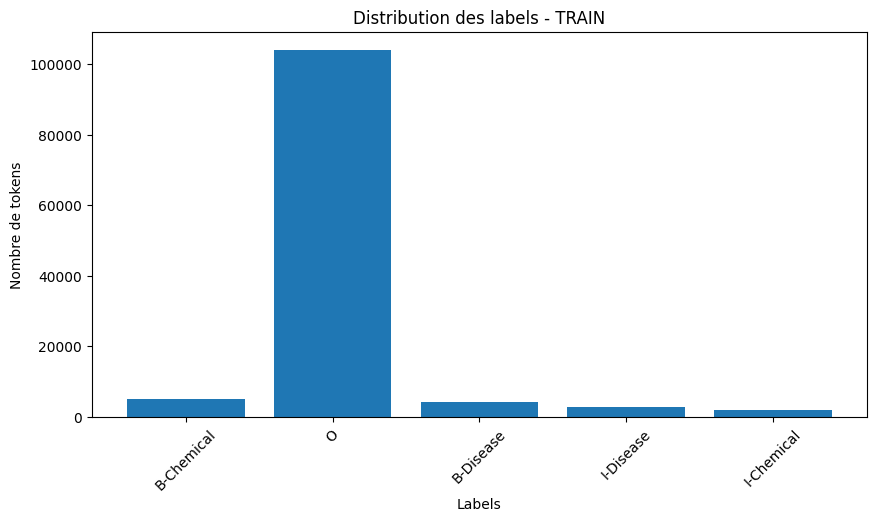

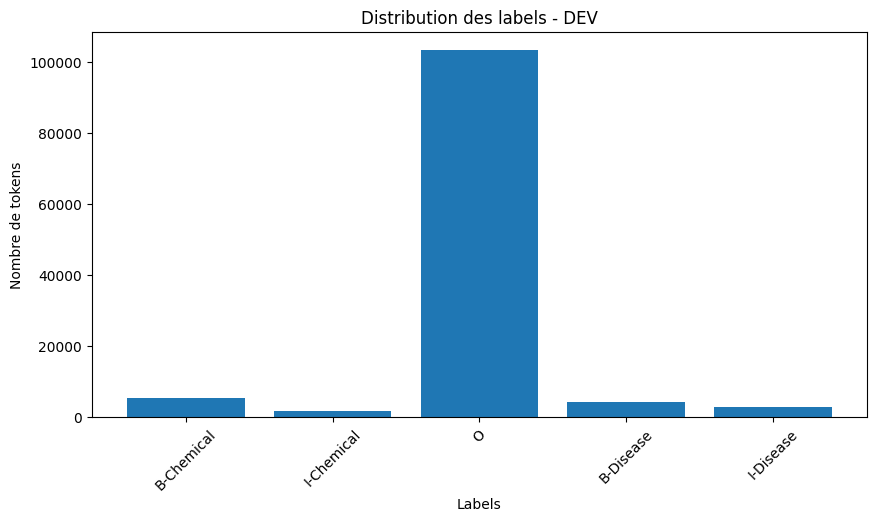

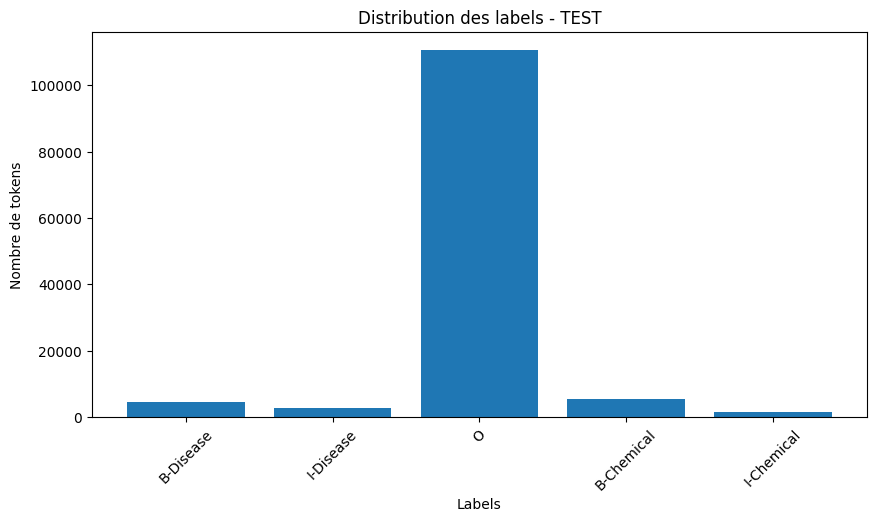

In [19]:
plot_label_distribution(train_data, "Distribution des labels - TRAIN")
plot_label_distribution(dev_data, "Distribution des labels - DEV")
plot_label_distribution(test_data, "Distribution des labels - TEST")

In [20]:
from collections import defaultdict

word2id = {"<PAD>":0, "<UNK>":1}

for sent in train_data:
    for w in sent["tokens"]:
        if w not in word2id:
            word2id[w] = len(word2id)

vocab_size = len(word2id)
print("Vocab size:", vocab_size)

Vocab size: 9983


In [21]:
!pip install pytorch-crf

In [22]:
from torchcrf import CRF
print("✔ torchcrf fonctionne sans restart")

✔ torchcrf fonctionne sans restart


In [23]:
import torch
from torch.utils.data import Dataset

word2id = {"<PAD>": 0, "<UNK>": 1}

for sent in train_data:
    for w in sent["tokens"]:
        if w not in word2id:
            word2id[w] = len(word2id)

vocab_size = len(word2id)
print("Vocab size:", vocab_size)


class LSTMDataset(Dataset):
    def __init__(self, data, word2id, label2id, max_len=128):
        self.data = data
        self.word2id = word2id
        self.label2id = label2id
        self.max_len = max_len

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        sent = self.data[idx]

        tokens = sent["tokens"]
        labels = sent["labels"]

        input_ids = [self.word2id.get(w, 1) for w in tokens]
        label_ids = [self.label2id[l] for l in labels]

        # padding
        input_ids = input_ids[:self.max_len]
        label_ids = label_ids[:self.max_len]

        input_ids += [0] * (self.max_len - len(input_ids))
        label_ids += [0] * (self.max_len - len(label_ids))

        return {
            "input_ids": torch.tensor(input_ids),
            "labels": torch.tensor(label_ids)
        }

Vocab size: 9983


In [24]:
train_ds_lstm = LSTMDataset(train_data, word2id, label2id)
dev_ds_lstm   = LSTMDataset(dev_data, word2id, label2id)

train_loader_lstm = DataLoader(train_ds_lstm, batch_size=32, shuffle=True)
dev_loader_lstm   = DataLoader(dev_ds_lstm, batch_size=32)

In [25]:
import torch
import torch.nn as nn
from torchcrf import CRF

class BiLSTM_CRF(nn.Module):
    def __init__(self, vocab_size, num_labels, pad_idx=0):
        super().__init__()

        self.pad_idx = pad_idx

        self.embedding = nn.Embedding(
            vocab_size,
            200,
            padding_idx=pad_idx
        )

        self.lstm = nn.LSTM(
            200,
            256,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(0.3)

        self.fc = nn.Linear(512, num_labels)

        self.crf = CRF(num_labels, batch_first=True)

    def forward(self, input_ids, labels=None, mask=None):

      if mask is None:
        mask = input_ids.ne(self.pad_idx)

      x = self.embedding(input_ids)
      x, _ = self.lstm(x)
      x = self.dropout(x)
      emissions = self.fc(x)

      if labels is not None:
        return -self.crf(emissions, labels, mask=mask)

    # 🔥 IMPORTANT FIX
      return self.crf.decode(emissions, mask=mask)

    

In [26]:
loss_history = []
f1_history = []
best_f1 = 0

In [30]:
from seqeval.metrics import f1_score

def eval_lstm(model, loader):

    model.eval()

    all_true = []
    all_pred = []

    with torch.no_grad():
        for batch in loader:

            inputs = batch["input_ids"].to(DEVICE)
            labels = batch["labels"].cpu().numpy()

            # 🔥 CRF OUTPUT = LIST (PAS logits)
            preds = model(inputs, mask=inputs.ne(0))

            for t_seq, p_seq in zip(labels, preds):

                true, pred = [], []

                for t, p in zip(t_seq, p_seq):

                    if t == -100:
                        continue

                    true.append(id2label[int(t)])
                    pred.append(id2label[int(p)])

                if len(true) > 0:
                    all_true.append(true)
                    all_pred.append(pred)

    return f1_score(all_true, all_pred)

In [40]:
from tqdm import tqdm

model = BiLSTM_CRF(vocab_size, len(label_list)).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)

best_path = "best_bilstm_crf.pt"

for epoch in range(15):

    model.train()
    total_loss = 0

    pbar = tqdm(train_loader_lstm, desc=f"Epoch {epoch+1}", leave=True)

    for batch in pbar:

        inputs = batch["input_ids"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        mask = inputs.ne(0)

        optimizer.zero_grad()

        loss = model(inputs, labels, mask)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        pbar.set_postfix(loss=loss.item())

    # 📉 LOSS
    avg_loss = total_loss / len(train_loader_lstm)
    loss_history.append(avg_loss)

    # 📊 F1 (accuracy séquence)
    f1 = eval_lstm(model, dev_loader_lstm)
    f1_history.append(f1)

    print(f"\n✅ Epoch {epoch+1} completed | Loss: {avg_loss:.4f} | F1: {f1:.4f}")

    # 💾 best model
    if f1 > best_f1:
        best_f1 = f1
        torch.save(model.state_dict(), best_path)

Epoch 1: 100%|██████████| 143/143 [01:01<00:00,  2.34it/s, loss=133]  



✅ Epoch 1 completed | Loss: 431.7147 | F1: 0.0894


Epoch 2: 100%|██████████| 143/143 [01:00<00:00,  2.37it/s, loss=111]



✅ Epoch 2 completed | Loss: 246.3478 | F1: 0.4303


Epoch 3: 100%|██████████| 143/143 [01:01<00:00,  2.34it/s, loss=72.6]



✅ Epoch 3 completed | Loss: 175.0859 | F1: 0.4997


... (18 outputs left out)

Epoch 14: 100%|██████████| 143/143 [01:01<00:00,  2.33it/s, loss=1.2] 



✅ Epoch 14 completed | Loss: 3.4252 | F1: 0.6000


Epoch 15: 100%|██████████| 143/143 [01:01<00:00,  2.32it/s, loss=0.928]



✅ Epoch 15 completed | Loss: 2.4869 | F1: 0.6104


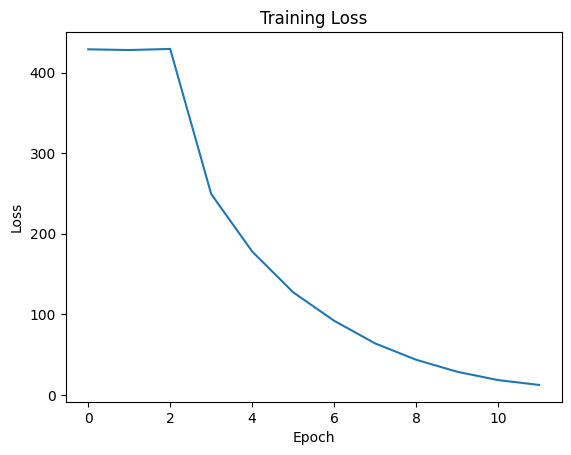

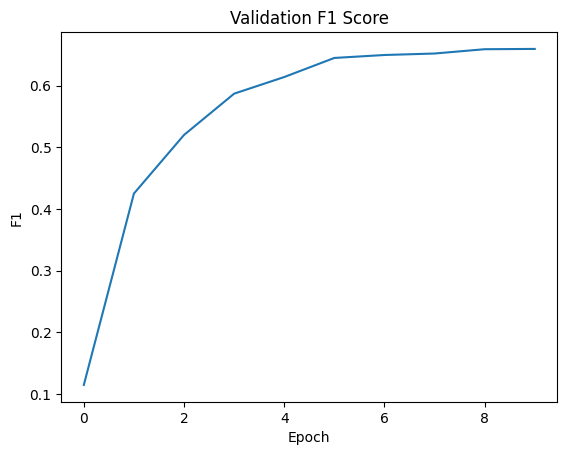

In [32]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(loss_history)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

plt.figure()
plt.plot(f1_history)
plt.title("Validation F1 Score")
plt.xlabel("Epoch")
plt.ylabel("F1")
plt.show()

In [33]:
from sklearn.metrics import classification_report

def get_report(model, loader):

    model.eval()
    all_true, all_pred = [], []

    with torch.no_grad():
        for batch in loader:

            inputs = batch["input_ids"].to(DEVICE)
            labels = batch["labels"].cpu().numpy()

            preds = model(inputs, mask=inputs.ne(0))

            for t_seq, p_seq in zip(labels, preds):

                for t, p in zip(t_seq, p_seq):

                    if t == -100:
                        continue

                    all_true.append(id2label[int(t)])
                    all_pred.append(id2label[int(p)])

    print(classification_report(all_true, all_pred, digits=4))

    return all_true, all_pred


y_true, y_pred = get_report(model, dev_loader_lstm)

              precision    recall  f1-score   support

  B-Chemical     0.7728    0.7424    0.7573      5342
   B-Disease     0.6897    0.6310    0.6590      4244
  I-Chemical     0.7875    0.4834    0.5991      1748
   I-Disease     0.5837    0.6353    0.6084      2723
           O     0.9647    0.9741    0.9694    103147

    accuracy                         0.9359    117204
   macro avg     0.7597    0.6933    0.7186    117204
weighted avg     0.9345    0.9359    0.9346    117204



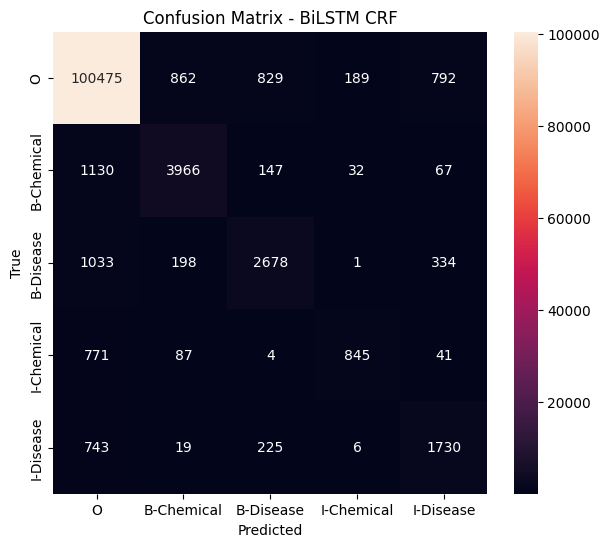

In [34]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels = list(label2id.keys())

cm = confusion_matrix(y_true, y_pred, labels=labels)

plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=labels,
            yticklabels=labels)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - BiLSTM CRF")
plt.show()

In [35]:
import os

save_dir = "bilstm_crf_model"
os.makedirs(save_dir, exist_ok=True)

In [36]:
import torch

model_path = os.path.join(save_dir, "model.pt")
torch.save(model.state_dict(), model_path)

In [37]:
import pickle

with open(os.path.join(save_dir, "word2id.pkl"), "wb") as f:
    pickle.dump(word2id, f)

In [38]:
import json

with open(os.path.join(save_dir, "label2id.json"), "w") as f:
    json.dump(label2id, f)

In [39]:
config = {
    "vocab_size": vocab_size,
    "num_labels": len(label_list),
    "embedding_dim": 200,
    "hidden_dim": 256
}

with open(os.path.join(save_dir, "config.json"), "w") as f:
    json.dump(config, f, indent=4)

In [41]:
import zipfile

zip_name = "bilstm_crf_model.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, _, files in os.walk(save_dir):
        for file in files:
            file_path = os.path.join(root, file)
            arcname = os.path.relpath(file_path, save_dir)
            zipf.write(file_path, arcname)

print("✔ Model saved as ZIP:", zip_name)

✔ Model saved as ZIP: bilstm_crf_model.zip
